# 06 — Évaluation finale et étude d'ablation
**Sujet 16 : Visual Anomaly Detection** — MVTec AD (`bottle`, `hazelnut`, `carpet`).

Rappel du pipeline et lien avec le cours :

| Étape du sujet | Réalisation | Cours |
|---|---|---|
| 1. Prétraitement | gris, 256×256 `INTER_AREA` ; **filtre médian 3×3** (objets) ; **normalisation locale** de l'éclairage (texture) ; **alignement** (centroïde Otsu, puis recherche de rotation). Variantes choisies par catégorie avec le critère sans étiquettes (section 4) | Ch. 2 (échantillonnage, histogrammes, transformations géométriques, interpolation) ; Ch. 3 (médian, passe-bas, régions) |
| 2. Caractéristiques | **histogrammes d'intensité par zone** (32 ou 16 px), moyenne, écart-type, contraste, Sobel, résidu \|I−I_ref\| ; **ORB / SIFT** en sac de mots visuels | Ch. 2 (histogrammes, soustraction d'images) ; Ch. 3 (Sobel) ; Ch. 1 (ORB, SIFT, Hamming) |
| 3. Apprentissage | **One-Class SVM** et **Isolation Forest** sur les seules images saines ; ACP ; validation croisée ; sélection par anomalies synthétiques | Ch. 1 (SVM, ACP) |
| 4. Reconnaissance | score > seuil → anomalie ; carte de chaleur ; contours, boîte, aire, centroïde | Ch. 3 (représentation des formes) |

Métriques : **AUROC** (mesure principale, indépendante du seuil), AP, précision, rappel, F1 au seuil du détecteur, rappel à taux de fausses alarmes fixé ; **AUROC pixel** et **IoU** pour la localisation.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, confusion_matrix
from src.data_loader import load_config
from src.evaluation import evaluate_detector

cfg = load_config(ROOT / "config.yaml"); CATS = cfg["data"]["categories"]
OUT = ROOT / "results" / "06_evaluation"; OUT.mkdir(parents=True, exist_ok=True)
E = {c: evaluate_detector(c, cfg) for c in CATS}
for c in CATS: print(f"{c:9s} {E[c]['info']['zone']} | agrégation {E[c]['info']['agrégation']} | seuil {E[c]['threshold']:.2f}")

C:\Users\Admin\Desktop\S9\Computer vision\projet_computer_vision\Visual Anomaly Detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


bottle    sans_histogramme | position | ocsvm(nu=0.05, gamma=0.02) | agrégation max | seuil 1.92
hazelnut  sans_histogramme | position | ocsvm(nu=0.05, gamma=scale) | agrégation max | seuil 1.68
carpet    sans_histogramme | shared | ocsvm(nu=0.05, gamma=0.5) | agrégation max | seuil 1.85


## 1. Niveau image : détection

In [2]:
cols = ["AUROC", "AP", "précision", "rappel", "F1", "exactitude", "taux fausses alarmes", "rappel @5% FA", "rappel @10% FA", "rappel @20% FA"]
img = pd.DataFrame({c: E[c]["image"] for c in CATS}).T
tab = img[cols].astype(float).round(3)
tab.insert(0, "défauts détectés", [f"{int(img.loc[c, 'VP'])}/{int(img.loc[c, 'VP'] + img.loc[c, 'FN'])}" for c in CATS])
tab.insert(1, "sains rejetés", [f"{int(img.loc[c, 'FP'])}/{int(img.loc[c, 'FP'] + img.loc[c, 'VN'])}" for c in CATS])
tab.to_csv(OUT / "tableau_image.csv"); tab

,défauts détectés,sains rejetés,AUROC,AP,précision,rappel,F1,exactitude,taux fausses alarmes,rappel @5% FA,rappel @10% FA,rappel @20% FA
bottle,61/63,3/20,0.990,0.997,0.953,0.968,0.961,0.940,0.150,0.952,0.968,0.968
hazelnut,51/70,6/40,0.846,0.914,0.895,0.729,0.803,0.773,0.150,0.629,0.714,0.800
carpet,35/89,1/28,0.779,0.923,0.972,0.393,0.560,0.530,0.036,0.528,0.528,0.539


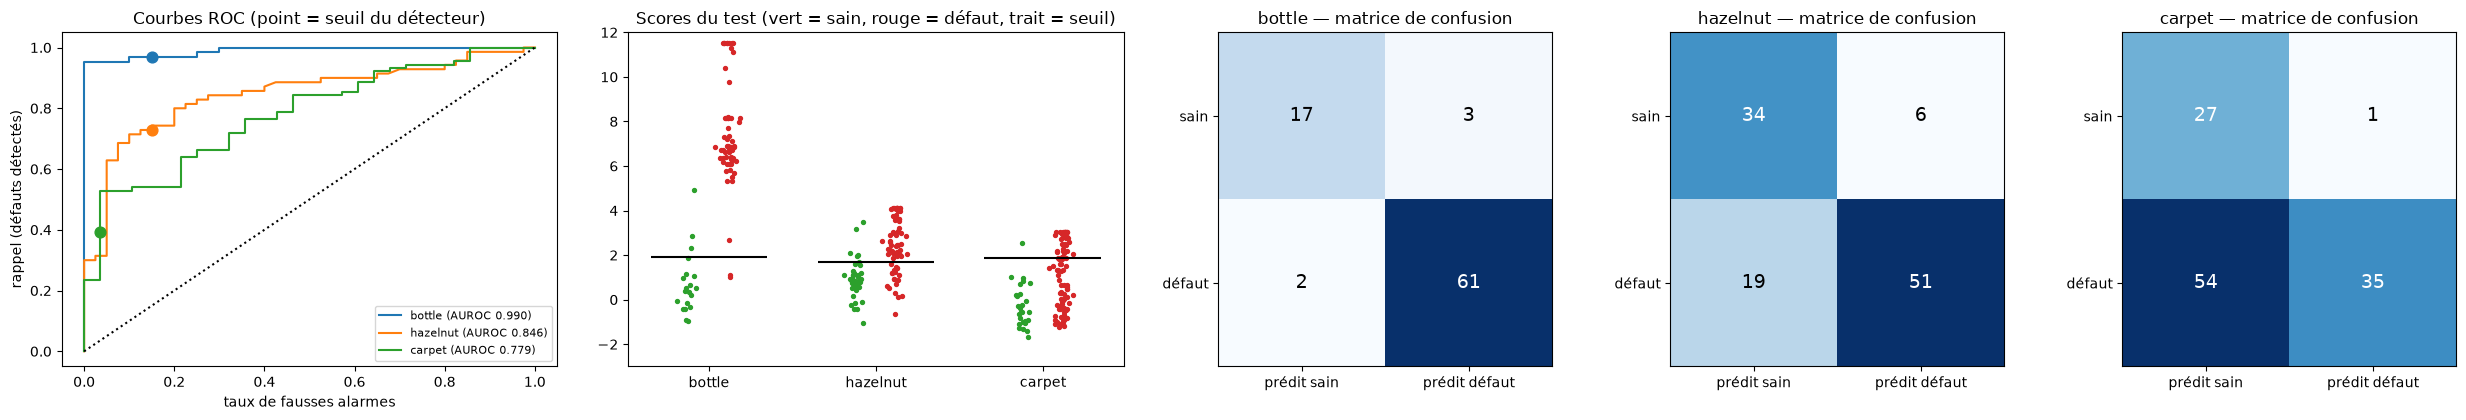

In [3]:
fig, axes = plt.subplots(1, 2 + len(CATS), figsize=(5 * (2 + len(CATS)), 4.3), gridspec_kw={"width_ratios": [1.3, 1.3] + [1] * len(CATS)})
for c in CATS:
    fpr, tpr, thr = roc_curve(E[c]["labels"], E[c]["scores"])
    axes[0].plot(fpr, tpr, label=f"{c} (AUROC {E[c]['image']['AUROC']:.3f})")
    m = E[c]["image"]; axes[0].scatter(m["taux fausses alarmes"], m["rappel"], s=60, zorder=3)
axes[0].plot([0, 1], [0, 1], "k:"); axes[0].set_xlabel("taux de fausses alarmes"); axes[0].set_ylabel("rappel (défauts détectés)")
axes[0].set_title("Courbes ROC (point = seuil du détecteur)"); axes[0].legend(fontsize=8)
for c in CATS:
    s, y = E[c]["scores"], E[c]["labels"]
    axes[1].scatter(np.full((y == 0).sum(), CATS.index(c) - 0.12) + np.random.default_rng(0).normal(0, 0.03, (y == 0).sum()), s[y == 0], s=8, c="tab:green")
    axes[1].scatter(np.full((y == 1).sum(), CATS.index(c) + 0.12) + np.random.default_rng(1).normal(0, 0.03, (y == 1).sum()), s[y == 1], s=8, c="tab:red")
    axes[1].hlines(E[c]["threshold"], CATS.index(c) - 0.35, CATS.index(c) + 0.35, colors="k")
axes[1].set_xticks(range(len(CATS))); axes[1].set_xticklabels(CATS); axes[1].set_ylim(-3, 12)
axes[1].set_title("Scores du test (vert = sain, rouge = défaut, trait = seuil)")
for ax, c in zip(axes[2:], CATS):
    cm = confusion_matrix(E[c]["labels"], (E[c]["scores"] > E[c]["threshold"]).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): ax.text(j, i, v, ha="center", va="center", fontsize=14, color="k" if v < cm.max() / 2 else "w")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["prédit sain", "prédit défaut"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["sain", "défaut"])
    ax.set_title(f"{c} — matrice de confusion")
plt.tight_layout(); plt.savefig(OUT / "roc_scores_confusion.png", dpi=110); plt.show()

## 2. Par type de défaut

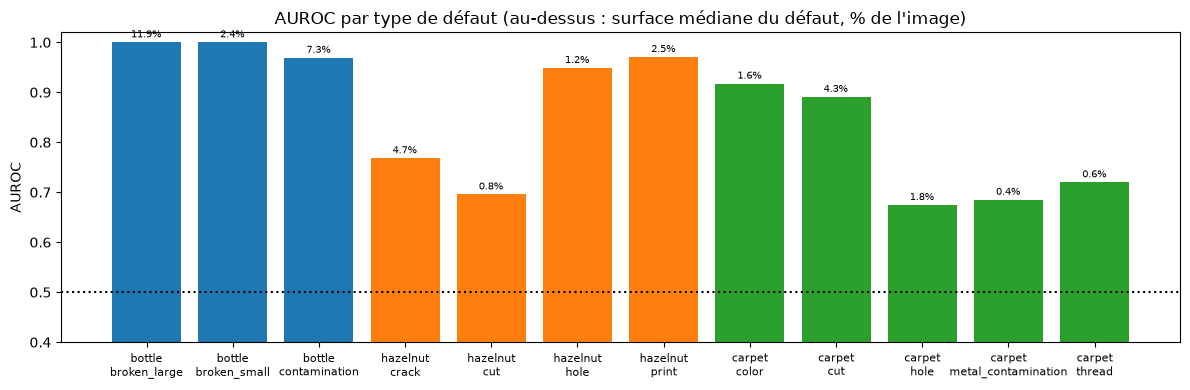

,catégorie,défaut,AUROC,surface médiane %
0,bottle,broken_large,1.000,11.874
1,bottle,broken_small,1.000,2.437
2,bottle,contamination,0.969,7.256
3,hazelnut,crack,0.768,4.727
4,hazelnut,cut,0.696,0.780
5,hazelnut,hole,0.949,1.246
6,hazelnut,print,0.971,2.496
7,carpet,color,0.917,1.569
8,carpet,cut,0.891,4.349
9,carpet,hole,0.674,1.836


In [4]:
dft = pd.DataFrame([{"catégorie": c, "défaut": d, "AUROC": v, "surface médiane %": 100 * np.median([m.mean() for m, x in zip(E[c]["masks"], E[c]["defects"]) if x == d])}
                    for c in CATS for d, v in E[c]["per_defect"].items()])
fig, ax = plt.subplots(figsize=(12, 4))
colors = {"bottle": "tab:blue", "hazelnut": "tab:orange", "carpet": "tab:green"}
ax.bar(dft["catégorie"] + "\n" + dft["défaut"], dft["AUROC"], color=[colors[c] for c in dft["catégorie"]])
ax.axhline(0.5, color="k", ls=":"); ax.set_ylim(0.4, 1.02); ax.set_ylabel("AUROC"); ax.tick_params(axis="x", labelsize=8)
for i, (a, s) in enumerate(zip(dft["AUROC"], dft["surface médiane %"])): ax.text(i, a + 0.01, f"{s:.1f}%", ha="center", fontsize=7)
ax.set_title("AUROC par type de défaut (au-dessus : surface médiane du défaut, % de l'image)")
plt.tight_layout(); plt.savefig(OUT / "auroc_par_defaut.png", dpi=110); plt.show()
dft.round(3).to_csv(OUT / "auroc_par_defaut.csv", index=False); dft.round(3)

## 3. Niveau pixel : localisation
Cartes d'anomalie dans l'espace aligné (256×256), comparées aux masques vérité terrain recalés par la même transformation.

In [5]:
pix = pd.DataFrame({c: E[c]["pixel"] for c in CATS}).T.astype(float).round(3); pix.to_csv(OUT / "tableau_pixel.csv"); pix

,AUROC pixel,IoU moyen (z>3),IoU médian
bottle,0.954,0.359,0.382
hazelnut,0.886,0.311,0.328
carpet,0.771,0.122,0.039


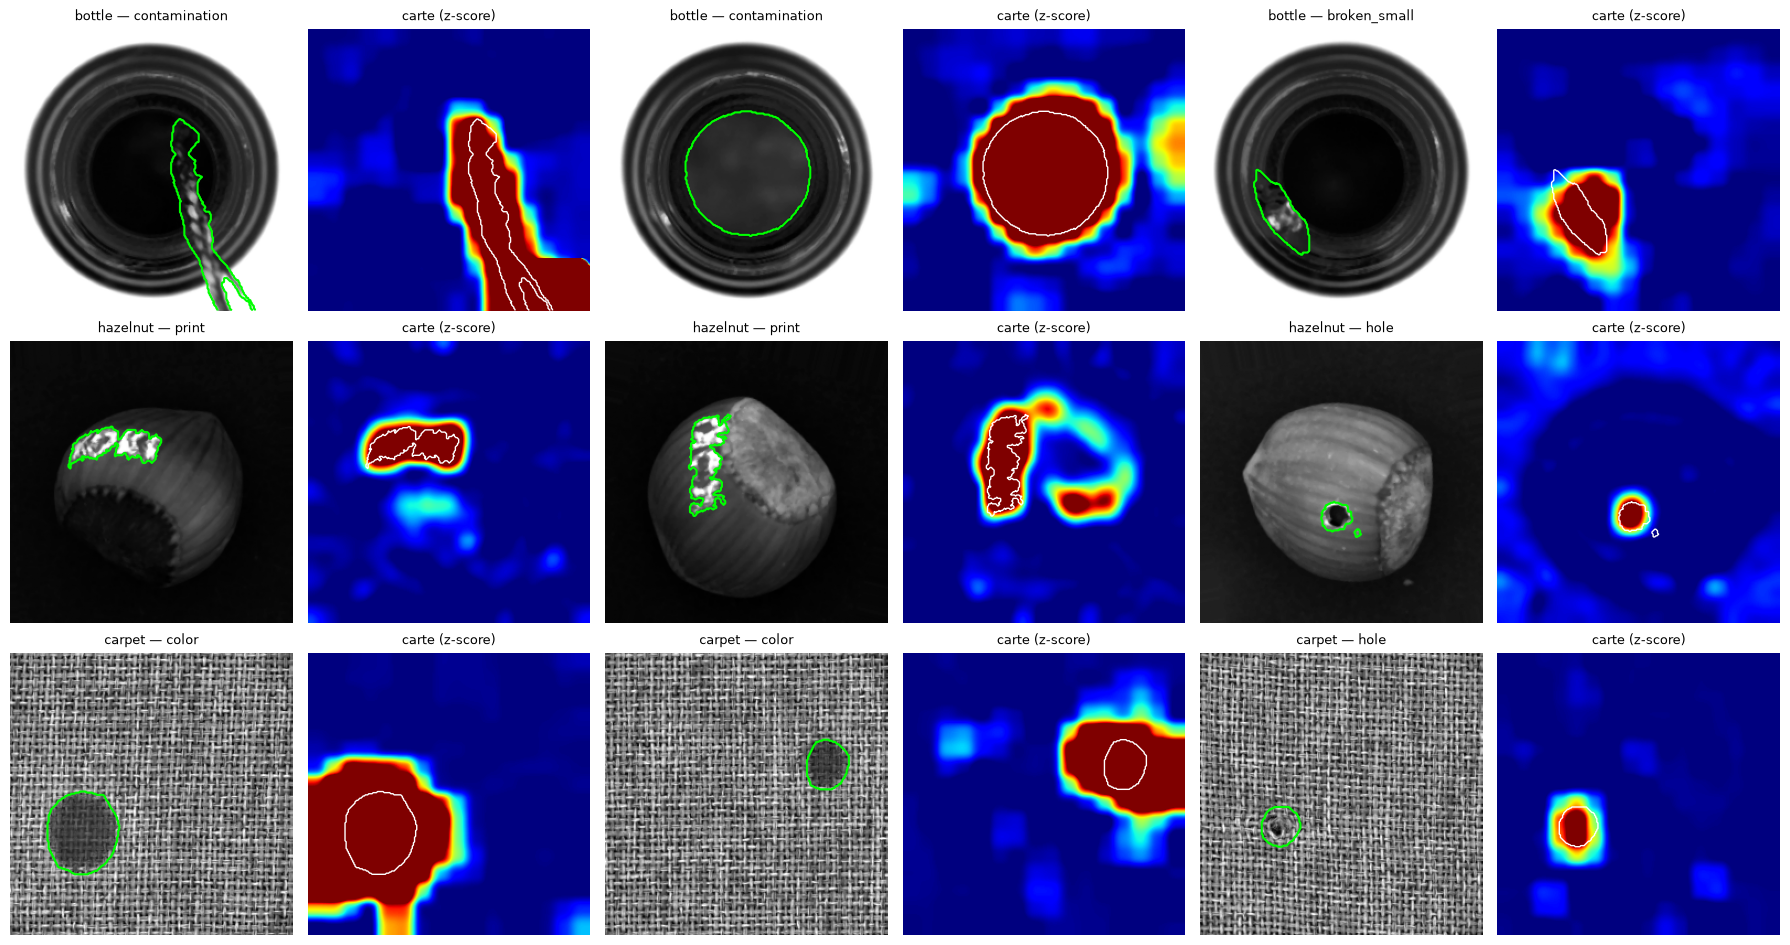

In [6]:
fig, axes = plt.subplots(len(CATS), 6, figsize=(18, 3.2 * len(CATS)))
for r, c in enumerate(CATS):
    e = E[c]; idx = [i for i in np.argsort(-e["scores"]) if e["labels"][i] == 1]
    picks = idx[:2] + idx[len(idx) // 2: len(idx) // 2 + 1]           # 2 plus forts + 1 médian
    for k, i in enumerate(picks):
        axes[r, 2 * k].imshow(e["images"][i], cmap="gray"); axes[r, 2 * k].contour(e["masks"][i], levels=[0.5], colors="lime")
        axes[r, 2 * k].set_title(f"{c} — {e['defects'][i]}", fontsize=9)
        axes[r, 2 * k + 1].imshow(np.clip(e["maps"][i], 0, 8), cmap="jet", vmin=0, vmax=8)
        axes[r, 2 * k + 1].contour(e["masks"][i], levels=[0.5], colors="white", linewidths=1); axes[r, 2 * k + 1].set_title("carte (z-score)", fontsize=9)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "localisation_exemples.png", dpi=100); plt.show()

## 4. Étude d'ablation : que rapporte chaque élément du pipeline ?
On retire ou remplace **un seul élément à la fois** par rapport au pipeline de l'étape 6 (la **référence**). La configuration du modèle reste fixe. Chaque variante est réentraînée avec le même protocole (validation croisée, anomalies synthétiques, seuil au 95e centile hors-pli) : **aucun vrai défaut** n'est utilisé pour l'entraîner. Δ = AUROC de la variante − AUROC de référence.

Cette étude sert **aussi à choisir le prétraitement final** : pour chaque catégorie, on retient la variante de prétraitement qui a le **meilleur critère synthétique** (section 4 bis). Les colonnes de test ne servent qu'au compte rendu.

In [7]:
ab = pd.concat([pd.read_csv(OUT / f"ablation_{c}.csv") for c in CATS])
ref = ab[ab["variante"] == "complet (référence)"].set_index("catégorie")["AUROC test"]
ab["Δ AUROC"] = ab["AUROC test"] - ab["catégorie"].map(ref)
show = ab.pivot_table(index="variante", columns="catégorie", values="AUROC test").round(3)[CATS]
order = ["complet (référence)", "sans filtre médian", "sans normalisation photométrique", "normalisation globale minmax (au lieu de locale)",
         "sans alignement", "zones 32 px (au lieu de 16)"] + sorted(v for v in show.index if v.startswith("famille"))
show = show.reindex([o for o in order if o in show.index]); show.to_csv(OUT / "ablation_auroc.csv"); show

catégorie,bottle,hazelnut,carpet
variante,,,
complet (référence),0.989,0.815,0.810
sans filtre médian,0.980,0.839,0.761
sans normalisation photométrique,0.990,0.901,0.465
normalisation globale minmax (au lieu de locale),NaN,NaN,0.709
sans alignement,0.986,0.789,NaN
zones 32 px (au lieu de 16),NaN,0.765,NaN
famille seule : histogramme,0.952,0.713,0.843
famille seule : residu,0.983,0.701,NaN
famille seule : sobel,0.976,0.879,0.575


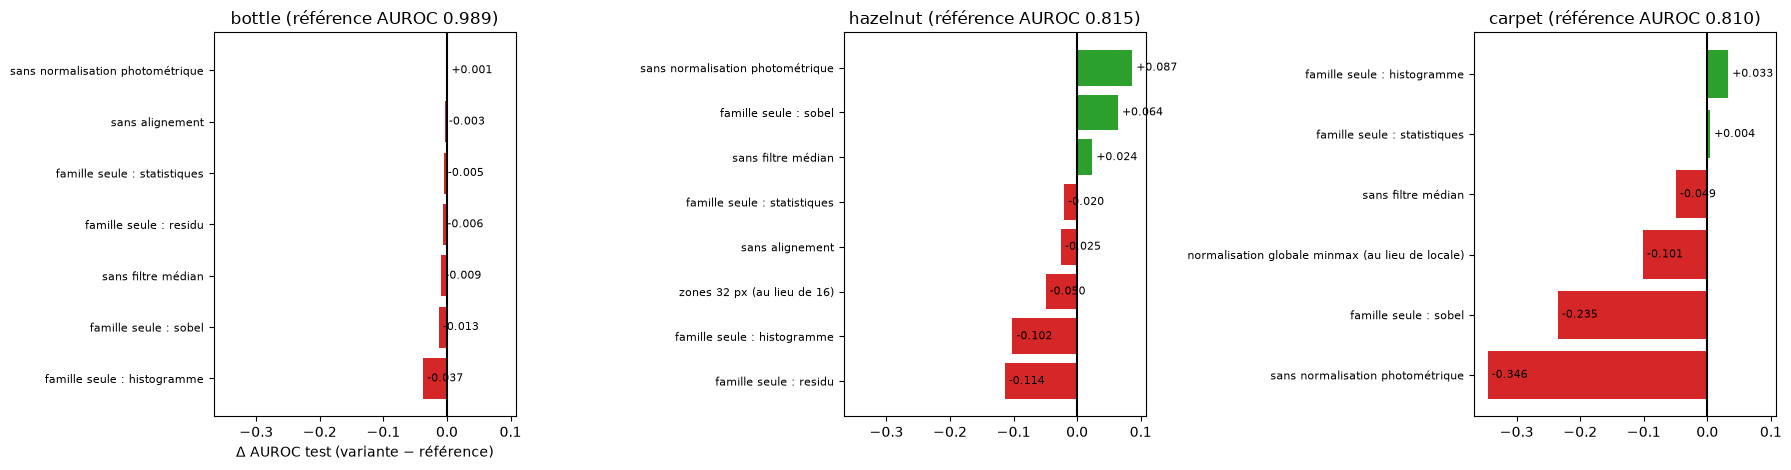

In [8]:
fig, axes = plt.subplots(1, len(CATS), figsize=(6 * len(CATS), 4.8), sharex=True)
for ax, c in zip(axes, CATS):
    d = ab[(ab["catégorie"] == c) & (ab["variante"] != "complet (référence)")].sort_values("Δ AUROC")
    ax.barh(d["variante"], d["Δ AUROC"], color=["tab:red" if v < 0 else "tab:green" for v in d["Δ AUROC"]])
    ax.axvline(0, color="k"); ax.set_title(f"{c} (référence AUROC {ref[c]:.3f})"); ax.tick_params(axis="y", labelsize=8)
    for y_, v in enumerate(d["Δ AUROC"]): ax.text(v, y_, f" {v:+.3f}", va="center", fontsize=8)
axes[0].set_xlabel("Δ AUROC test (variante − référence)")
plt.tight_layout(); plt.savefig(OUT / "ablation.png", dpi=110); plt.show()
ab.round(3).to_csv(OUT / "ablation_complete.csv", index=False)

In [9]:
det_rows = ab.pivot_table(index="variante", columns="catégorie", values=["F1", "taux fausses alarmes"]).round(3)
det_rows.reindex([o for o in order if o in det_rows.index])

F1                  \
catégorie                                        bottle carpet hazelnut   
variante                                                                  
complet (référence)                               0.968  0.729    0.382   
sans filtre médian                                0.961  0.349    0.500   
sans normalisation photométrique                  0.961  0.541    0.868   
normalisation globale minmax (au lieu de locale)    NaN  0.421      NaN   
sans alignement                                   0.960    NaN    0.368   
zones 32 px (au lieu de 16)                         NaN    NaN    0.440   
famille seule : histogramme                       0.922  0.764    0.511   
famille seule : residu                            0.961    NaN    0.400   
famille seule : sobel                             0.945  0.504    0.716   
famille seule : statistiques                      0.960  0.553    0.329   

                                                 taux fausses alarmes         \
catégorie                                                      bottle carpet   
variante                                                                       
complet (référence)                                              0.10  0.000   
sans filtre médian                                               0.15  0.036   
sans normalisation photométrique                                 0.15  0.286   
normalisation globale minmax (au lieu de locale)                  NaN  0.036   
sans alignement                                                  0.10    NaN   
zones 32 px (au lieu de 16)                                       NaN    NaN   
famille seule : histogramme                                      0.30  0.000   
famille seule : residu                                           0.15    NaN   
famille seule : sobel                                            0.20  0.214   
famille seule : statistiques                                     0.10  0.000   

                                                           
catégorie                                        hazelnut  
variante                                                   
complet (référence)                                 0.050  
sans filtre médian                                  0.050  
sans normalisation photométrique                    0.075  
normalisation globale minmax (au lieu de locale)      NaN  
sans alignement                                     0.025  
zones 32 px (au lieu de 16)                         0.025  
famille seule : histogramme                         0.000  
famille seule : residu                              0.050  
famille seule : sobel                               0.000  
famille seule : statistiques                        0.025

## 4 bis. Choix du prétraitement final par le critère sans étiquettes
Variantes de **prétraitement** uniquement : les variantes « famille seule » portent sur les caractéristiques et sont déjà couvertes par la grille de sélection de l'étape 6. Le choix se fait sur la colonne *critère synthétique* ; l'AUROC de test est donnée pour information.

In [10]:
pre_var = ["complet (référence)", "sans filtre médian", "sans normalisation photométrique",
           "normalisation globale minmax (au lieu de locale)", "sans alignement", "zones 32 px (au lieu de 16)"]
rows = []
for c in CATS:
    d = ab[(ab["catégorie"] == c) & ab["variante"].isin(pre_var)]
    best = d.loc[d["AUROC synthétique"].idxmax(), "variante"]
    for _, r in d.iterrows():
        rows.append({"catégorie": c, "variante": r["variante"], "critère synthétique": round(r["AUROC synthétique"], 3),
                     "AUROC test (rapport)": round(r["AUROC test"], 3), "retenue": "✔" if r["variante"] == best else ""})
choix = pd.DataFrame(rows); choix.to_csv(OUT / "choix_pretraitement.csv", index=False); choix

,catégorie,variante,critère synthétique,AUROC test (rapport),retenue
0,bottle,complet (référence),0.980,0.989,
1,bottle,sans filtre médian,0.972,0.980,
2,bottle,sans normalisation photométrique,0.996,0.990,✔
3,bottle,sans alignement,0.970,0.986,
4,hazelnut,complet (référence),0.795,0.815,
5,hazelnut,sans filtre médian,0.829,0.839,
6,hazelnut,sans normalisation photométrique,0.833,0.901,✔
7,hazelnut,sans alignement,0.795,0.789,
8,hazelnut,zones 32 px (au lieu de 16),0.724,0.765,
9,carpet,complet (référence),0.900,0.810,


## 5. Comparaisons de modèles (rappel de l'étape 6)
Dans chaque groupe, la configuration choisie **par le critère synthétique**, et son AUROC de test.

In [11]:
cmp_ = pd.read_csv(ROOT / "results" / "04_apprentissage" / "comparaisons.csv")
cmp_.pivot_table(index=["comparaison", "valeur"], columns="catégorie", values="AUROC test").round(3)[CATS]

catégorie                              bottle  hazelnut  carpet
comparaison          valeur                                    
caractéristiques     residu_sobel       0.975     0.652   0.791
                     sans_histogramme   0.990     0.846   0.779
                     toutes             0.962     0.425   0.787
combinaison          zones + global     0.979     0.827   0.675
                     zones seules       0.990     0.846   0.779
global ORB/SIFT seul iforest            0.848     0.614   0.447
                     ocsvm              0.910     0.656   0.449
modèle               iforest            0.967     0.588   0.806
                     ocsvm              0.990     0.846   0.779
stratégie            position           0.990     0.846   0.757
                     shared             0.966     0.911   0.779

## Conclusions finales

### Résultats des détecteurs finaux (test MVTec AD, aucun vrai défaut utilisé pour entraîner, choisir ou fixer le seuil)

| | AUROC | AP | F1 | rappel | fausses alarmes | AUROC pixel | IoU moyen |
|---|---|---|---|---|---|---|---|
| **bottle** | **0,990** | 0,997 | **0,961** | 97 % | 3/20 | **0,954** | 0,36 |
| **hazelnut** | 0,846 | 0,914 | 0,803 | 73 % | 6/40 | 0,886 | 0,31 |
| **carpet** | 0,779 | 0,923 | 0,560 | 39 % | 1/28 | 0,771 | 0,12 |

**Par type de défaut** : les défauts **grands ou contrastés** sont très bien détectés (bouteille cassée 1,00 ; impression sur noisette 0,97 ; trou de noisette 0,95 ; tache de couleur sur tapis 0,92). Les défauts **fins ou minuscules** le sont mal : coupure de noisette 0,70 (0,8 % de l'image), contamination métallique du tapis 0,69 (0,4 %), fil 0,72, trou du tapis 0,67.

### Ce que montre l'étude d'ablation (lien avec le cours)
- **Normalisation de l'éclairage (Ch. 2 et 3).** Indispensable pour la **texture** : sans elle, carpet tombe à 0,465 ; avec une normalisation globale `minmax` au lieu de locale, 0,709. Pour les objets à fond uniforme, elle est inutile, voire nuisible (hazelnut).
- **Alignement (Ch. 2 : rotation, translation, interpolation).** Gain faible mais constant sur les objets (bottle −0,003 et hazelnut −0,025 sans alignement).
- **Taille des zones.** Des zones de 16 px plutôt que 32 px améliorent hazelnut (+0,05), dont les défauts sont fins.
- **Filtre médian (Ch. 3).** Effet faible et variable. Les images MVTec sont peu bruitées : le médian sert de protection contre les pixels aberrants. Le critère l'a retiré pour carpet, mais au test cela fait perdre 0,05 : le critère s'est trompé sur ce choix.
- **Caractéristiques.** Le résidu |I−I_ref| (soustraction d'images) et les statistiques d'intensité par zone sont les plus utiles pour les objets alignés ; l'histogramme par zone, pour la texture. Les descripteurs **ORB/SIFT** (Ch. 1) utilisés globalement, en sac de mots visuels, sont nettement moins bons (0,45 à 0,91) et n'ont jamais été retenus.
- **Modèles.** L'OC-SVM et l'Isolation Forest donnent des résultats proches. Le choix entre un modèle **par position** et un modèle **partagé** dépend de la qualité de l'alignement.

### Limites et honnêteté méthodologique
1. **Le critère de sélection par anomalies synthétiques** est fiable pour bottle, mais pas pour hazelnut ni carpet. Les vrais défauts ressemblent trop peu aux défauts simulés : de meilleures configurations existaient dans la grille, mais le critère ne les a pas reconnues.
2. **Fausses alarmes** : 15 % sur bottle et hazelnut (cible 5 %), à cause d'un décalage d'éclairage entre les images d'apprentissage et de test, et de petits effectifs (20 et 40 images saines de test).
3. **Biais corrigé :** à l'étape 4, la normalisation `minmax` avait été choisie avec une mesure qui utilisait les images saines du test. À l'étape 8, tout le prétraitement a été choisi à nouveau par le critère sans étiquettes (option B).
4. **Localisation grossière :** les cartes ont la résolution des zones (IoU entre 0,12 et 0,36), ce qui surestime l'aire des défauts.
5. **Approche classique :** caractéristiques manuelles, alignement rigide et modèles à une classe. Elle atteint ses limites sur les produits naturels de forme variable (hazelnut) et sur les défauts de moins de 1 % de l'image. Les méthodes à réseaux profonds pré-entraînés (hors du périmètre du sujet) obtiennent de meilleurs résultats sur ces cas.